# Behind GoEmotions: exploratory analysis and preprocessing

This notebook is dedicated to the initial exploratory analysis and the preparation pipeline of the **GoEmotions** dataset. The goal is to analyze the original distribution of emotions, observe the complexity of multi-label data, and balance the dataset for subsequent modeling phases.

## Notebook objectives
1. **Exploratory analysis**: analyze the structure of the entire dataset and map the distribution of the 28 original emotion categories.
2. **Single-label filtering**: exclusively select comments associated with a single emotion to simplify the classification task from multi-label to single-label multi-class.
3. **Resampling**: handle severe class imbalance via undersampling or oversampling strategies.
4. **Text preprocessing**: standardization of comment text.
5. **Distribution validation**: visualize and compare the new post-processing label breakdown to verify the effectiveness of balancing.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/Behind_GoEmotions'

import os
os.chdir(PROJECT_ROOT)

DATA_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed')
EDA_FIGURE_PATH = os.path.join(PROJECT_ROOT, 'results', 'eda')

print("Current working directory:", os.getcwd())

Mounted at /content/drive
Current working directory: /content/drive/MyDrive/Behind_GoEmotions


In [3]:
# libraries import
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import tensorflow_datasets as tfds

import re
import spacy
from wordcloud import WordCloud

import warnings
warnings.filterwarnings('ignore')

## Dataset import
In this section, the GoEmotions dataset is imported from the TensorFlow Datasets API.

In [4]:
# dataset import
dataset_train, info = tfds.load('goemotions', split='train', with_info=True)
dataset_test, info = tfds.load('goemotions', split='test', with_info=True)
dataset_val, info = tfds.load('goemotions', split='validation', with_info=True)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/goemotions/incomplete.09KGP1_0.1.0/goemotions-train.tfrecord-[0-9][0-9][0-…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/goemotions/incomplete.09KGP1_0.1.0/goemotions-validation.tfrecord-[0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/goemotions/incomplete.09KGP1_0.1.0/goemotions-test.tfrecord-[0-9][0-9][0-9…

Dataset goemotions downloaded and prepared to /root/tensorflow_datasets/goemotions/0.1.0. Subsequent calls will reuse this data.


In [5]:
df_train = tfds.as_dataframe(dataset_train, info)
df_test = tfds.as_dataframe(dataset_test, info)
df_val = tfds.as_dataframe(dataset_val, info)

In [6]:
# utf-8 decoding to remove b"..." patterns
df_train['comment_text'] = df_train['comment_text'].str.decode('utf-8')
df_test['comment_text'] = df_test['comment_text'].str.decode('utf-8')
df_val['comment_text'] = df_val['comment_text'].str.decode('utf-8')
df_full = pd.concat([df_train, df_test, df_val])

## Observations on dataset split and data cleaning
The original dataset has > 58k Reddit comments and is already split into train, test, and validation partitions by TensorFlow.

Two data cleaning operations were performed:
- Removal of rows containing missing values
- Removal of duplicate rows

In [33]:
# split dimensions
print(f"Train split shape:        {df_train.shape}")
print(f"Test split shape:         {df_test.shape}")
print(f"Validation split shape:   {df_val.shape}")

Train split shape:        (43297, 29)
Test split shape:         (5422, 29)
Validation split shape:   (5424, 29)


In [8]:
# data cleaning: na removal

print(f"na values in training set: {df_train.isna().sum()}")
#print(f"na values in test set: {df_test.isna().sum()}")
#print(f"na values in validation set: {df_val.isna().sum()}")
df_train.dropna(inplace=True)
df_test.dropna(inplace=True)
df_val.dropna(inplace=True)

na values in training set: admiration        0
amusement         0
anger             0
annoyance         0
approval          0
caring            0
comment_text      0
confusion         0
curiosity         0
desire            0
disappointment    0
disapproval       0
disgust           0
embarrassment     0
excitement        0
fear              0
gratitude         0
grief             0
joy               0
love              0
nervousness       0
neutral           0
optimism          0
pride             0
realization       0
relief            0
remorse           0
sadness           0
surprise          0
dtype: int64


In [9]:
# data cleaning: duplicate removal

print(f"Duplicate values in training set:   {df_train.duplicated().sum()}")
print(f"Duplicate values in test set:       {df_test.duplicated().sum()}")
print(f"Duplicate values in validation set: {df_val.duplicated().sum()}")

df_train.drop_duplicates(inplace=True)
df_test.drop_duplicates(inplace=True)
df_val.drop_duplicates(inplace=True)

Duplicate values in training set:   113
Duplicate values in test set:       5
Duplicate values in validation set: 2


In [10]:
train_sample = pd.DataFrame.sample(df_train, n=3, random_state=42).style.hide(axis="index")
train_sample

admiration,amusement,anger,annoyance,approval,caring,comment_text,confusion,curiosity,desire,disappointment,disapproval,disgust,embarrassment,excitement,fear,gratitude,grief,joy,love,nervousness,neutral,optimism,pride,realization,relief,remorse,sadness,surprise
False,False,False,False,False,False,Must not hit opponents on the first frame then. My mistake,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
False,False,False,False,False,False,"Yo, was that NDP leader [NAME] on the sidelines?",True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
False,False,False,False,False,False,38 yrs. It was worth it though.,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False


> Labels are encoded with boolean values. During the exploratory analysis, we will use the original dataset with light data cleaning.

## Exploratory analysis
In this section, we show the main characteristics of the dataset to understand the distribution.
Specifically, we represent:
- General label distribution
- Label co-occurrence
- Single-label vs multi-label frequency
- Number of labels per sample (1-5)
- Most frequent emotion pairs
- Text length distribution

### General label distribution
We visualize the label distribution in the original dataset, which reveals a strong disparity in frequency, with some emotions appearing thousands of times and others with fewer than 1000 observations.

From this visualization, it is natural to wonder whether the models to be trained will be able to correctly classify the less common labels.

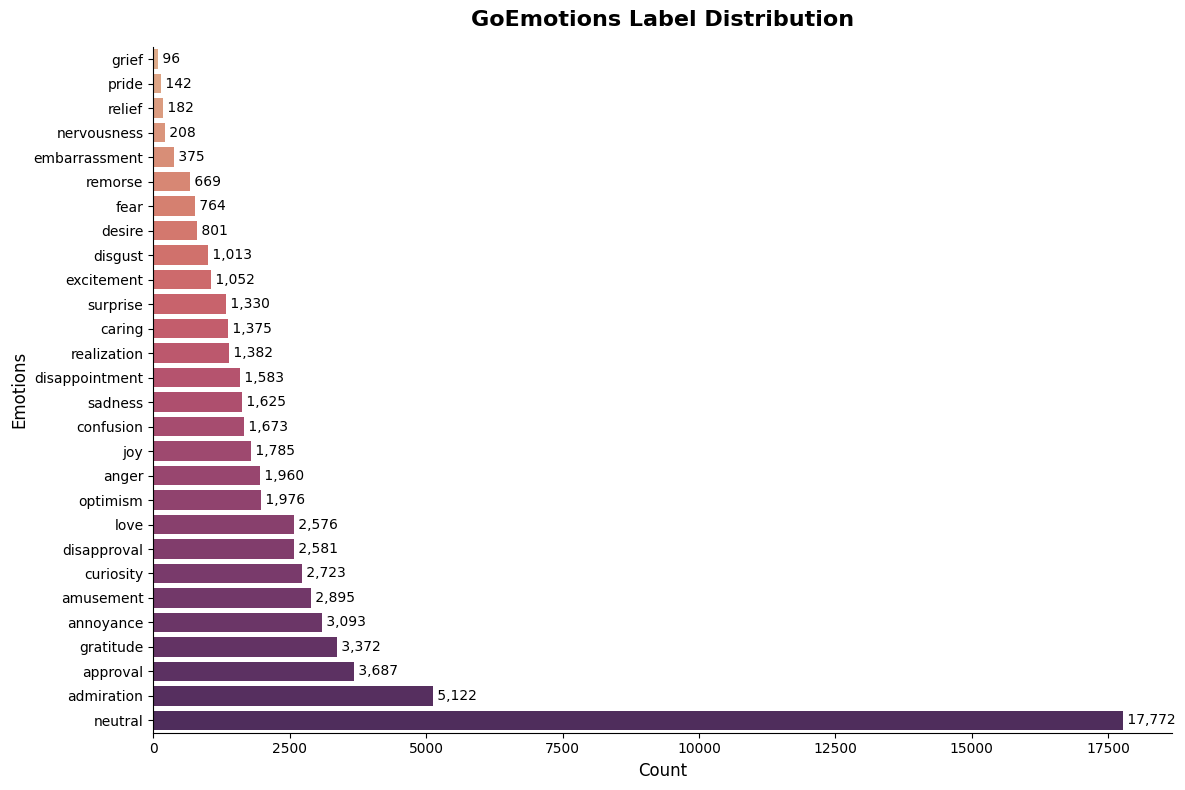

In [11]:
file_name = "label_distribution.png"

# list with dataset emotions
label_names = [col for col in df_full.columns if col != 'comment_text']

# sum of occurrences per emotion
label_counts = df_full[label_names].sum().sort_values(ascending=False)

# counts in ascending order
label_counts_sorted = label_counts.sort_values(ascending=True)

plt.figure(figsize=(12, 8))

# color palette setting
sns.barplot(
    x=label_counts_sorted.values,
    y=label_counts_sorted.index,
    palette="flare"
)

# numeric values for each label
for index, value in enumerate(label_counts_sorted.values):
    plt.text(value, index, f' {value:,}', va='center', fontsize=10)

plt.title("GoEmotions Label Distribution", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Count", fontsize=12)
plt.ylabel("Emotions", fontsize=12)

# removal of right and top spines
sns.despine(right=True, top=True)

plt.tight_layout()
plt.savefig(os.path.join(EDA_FIGURE_PATH, file_name))
plt.show()

### Co-occurrence matrix
From the matrix, it can be observed that pairs of emotions commonly perceived as positive or negative tend to co-occur within the same text.

Some examples are:
- gratitude, admiration
- sadness, disappointment
- anger, annoyance

Other easily observable co-occurrences stem from emotions that tend to express themselves verbally with similar semantics and/or syntax, such as curiosity and confusion.

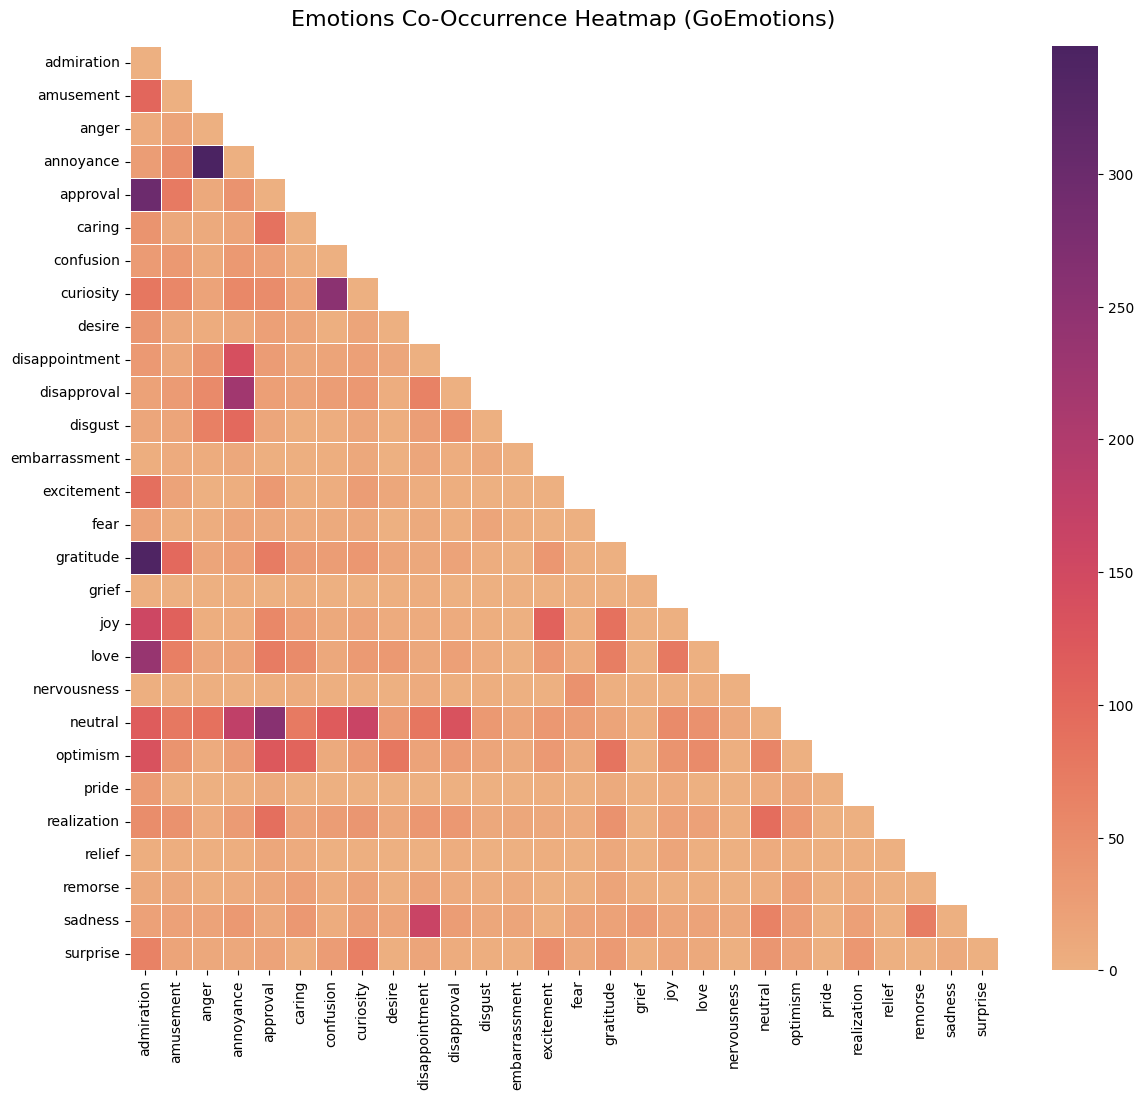

In [12]:
file_name = "co_occurrence_matrix.png"

# df with True and False on emotions
df_labels = df_full[label_names].astype(int) # cast from bool to int

# 28x28 co-occurrence matrix
co_occurrence_matrix = df_labels.T.dot(df_labels) # version with diagonal
co_occurrence_matrix_diag = co_occurrence_matrix.copy().astype(float) # version to zero out diagonal

# zero out diagonal: exclude how many times an emotion appears alone
np.fill_diagonal(co_occurrence_matrix_diag.values, 0)

# zero out matrix above the diagonal excluding already zeroed diagonal
mask = np.triu_indices(len(co_occurrence_matrix_diag), k=1)
co_occurrence_matrix_diag.values[mask] = np.nan

# plot heatmap
plt.figure(figsize=(14, 12))
sns.heatmap(
    co_occurrence_matrix_diag,
    cmap="flare",
    annot=False, # exclude annotations: 28 classes are too many
    linewidths=.5
)
plt.title("Emotions Co-Occurrence Heatmap (GoEmotions)", fontsize=16, pad=15)
plt.savefig(os.path.join(EDA_FIGURE_PATH, file_name))
plt.show()

### Co-occurrence analysis


### Single-label vs multi-label frequency
We observe that the dataset consists of over 80% single-label observations, so we hypothesize that after resampling it will be possible to have a more representative dataset with a sufficient number of samples for the analysis.

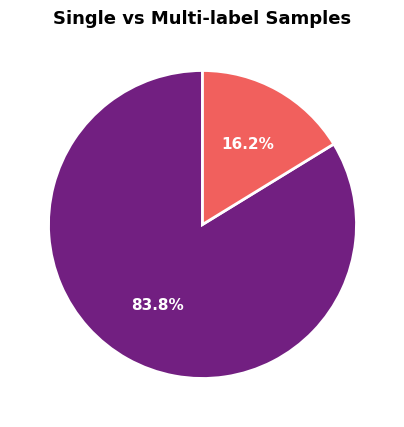

In [13]:
file_name = "single_multi_labels.png"

# how many labels for each row
labels_per_sample = df_full[label_names].sum(axis=1)

# count how many texts have 0, 1, 2... labels and sort by the number of labels
distribution = labels_per_sample.value_counts().sort_index()

multi_label = (labels_per_sample > 1).sum()
single_label = (labels_per_sample == 1).sum()

plt.figure(figsize=(5,5))

colors = sns.color_palette("magma", 2)

plt.pie(
    [single_label, multi_label],
    labels=["Single-label", "Multi-label"],
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    textprops={'fontsize': 11, 'weight': 'bold', 'color': 'white'},
    wedgeprops={'edgecolor': 'w', 'linewidth': 2}
    )

plt.title("Single vs Multi-label Samples", fontsize=13, weight='bold')
plt.savefig(os.path.join(EDA_FIGURE_PATH, file_name))
plt.show()

### Number of labels per sample (1-5)
Multiple labels, besides being overall fewer than single ones, appear less frequently as the number of emotions per sample increases.

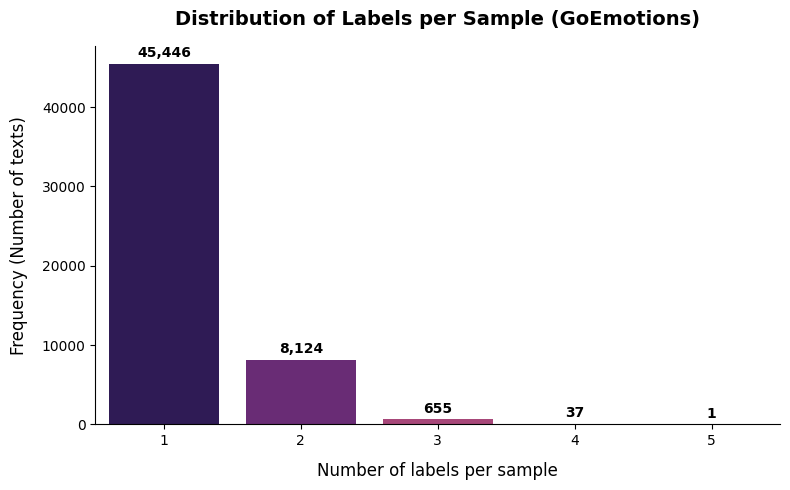

In [14]:
file_name = "labels_per_sample.png"

plt.figure(figsize=(8, 5))

# standard vertical barplot
sns.barplot(
    x=distribution.index,
    y=distribution.values,
    palette="magma"
)

# numeric values above each bar
for index, value in enumerate(distribution.values):
    plt.text(
        index,          # x position (the center of the bar)
        value + (max(distribution.values) * 0.01),  # y position (slightly above the bar)
        f'{value:,}',
        ha='center',    # horizontal alignment to the center
        va='bottom',    # vertical alignment
        fontsize=10,
        fontweight='bold'
    )

# adjust labels and axes
plt.xlabel("Number of labels per sample", fontsize=12, labelpad=10)
plt.ylabel("Frequency (Number of texts)", fontsize=12, labelpad=10)
plt.title("Distribution of Labels per Sample (GoEmotions)", fontsize=14, fontweight='bold', pad=15)

# removal of right and top spines
sns.despine(right=True, top=True)

plt.tight_layout()
plt.savefig(os.path.join(EDA_FIGURE_PATH, file_name))
plt.show()

### Most frequent emotion pairs
From the co-occurrence matrix, it was observed that many co-occurrences happen with the neutral label, so we chose to create a more effective representation with the most frequent emotion pairs, excluding the neutral attribute from the count as it is not very informative.

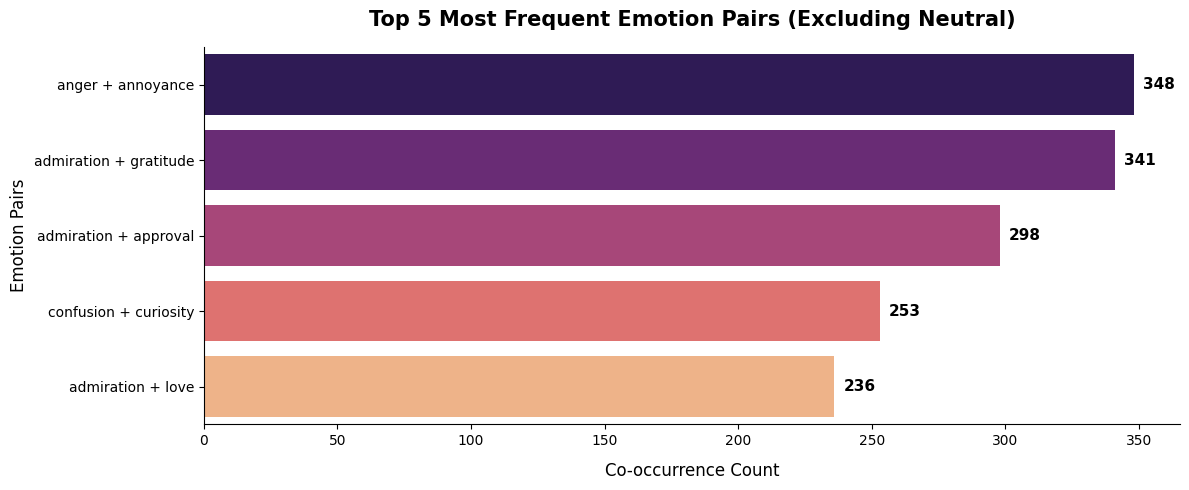

In [15]:
file_name = "most_freq_emotion_pairs.png"

co_occurrence_for_pairs = co_occurrence_matrix.copy()
np.fill_diagonal(co_occurrence_for_pairs.values, 0)

# exclude 'neutral' by zeroing out its row and column in the temporary matrix
matrix_no_neutral_for_pairs = co_occurrence_for_pairs.drop(index='neutral', columns='neutral', errors='ignore')

# only the upper triangular part of the matrix to avoid counting pairs twice
upper_tri = matrix_no_neutral_for_pairs.where(np.triu(np.ones(matrix_no_neutral_for_pairs.shape), k=1).astype(bool))

# unroll the matrix (stack) to transform it into a list of pairs with their relative values
pairs_series = upper_tri.stack().sort_values(ascending=False)

# take the top 5 most frequent pairs
top_5_pairs = pairs_series.head(5)

# readable strings for the pairs to pass to the plot
pair_labels = [f"{emotion_1} + {emotion_2}" for (emotion_1, emotion_2) in top_5_pairs.index]
pair_values = top_5_pairs.values

plt.figure(figsize=(12, 5))

# horizontal bar plot
sns.barplot(
    x=pair_values,
    y=pair_labels,
    palette="magma",
    hue=pair_labels, # avoids Seaborn warnings for palettes
    legend=False
)

# addition of exact numeric value at the end of each bar
for index, value in enumerate(pair_values):
    plt.text(
        value + (max(pair_values) * 0.01), # x: slightly after the bar
        index,                             # y: centered on the bar
        f'{int(value):,}',
        va='center',
        ha='left',
        fontsize=11,
        fontweight='bold'
    )

plt.title("Top 5 Most Frequent Emotion Pairs (Excluding Neutral)", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Co-occurrence Count", fontsize=12, labelpad=10)
plt.ylabel("Emotion Pairs", fontsize=12)

# removal of right and top spines
sns.despine(right=True, top=True)

plt.tight_layout()
plt.savefig(os.path.join(EDA_FIGURE_PATH, file_name))
plt.show()

### Text length distribution
The reference texts have a mostly uniform distribution with the third quartile falling within 100 characters per comment.

Most of the texts in the dataset have a contained length, with the exception of a few outliers.

In any case, the texts do not exceed 700 characters, although the maximum limit on Reddit is 10,000. This is probably a choice in the creation of the dataset to avoid overly long comments that could present an excessively broad context and consequently distort the classification.

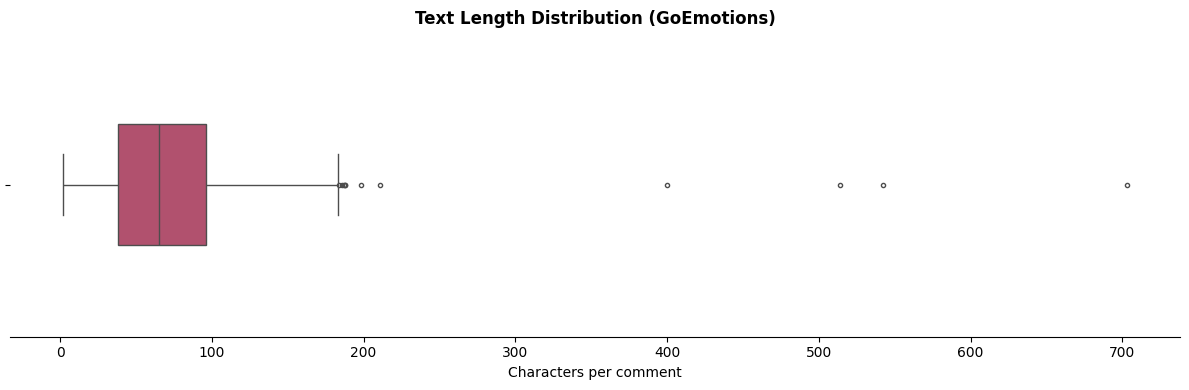

In [16]:
file_name = "text_length_distribution_characters.png"

# calculate the number of characters per comment
df_full['text_length'] = df_full['comment_text'].astype(str).str.len()

plt.figure(figsize=(12, 4))

# horizontal boxplot
sns.boxplot(
    x=df_full['text_length'],
    palette="flare",
    width=0.4,
    fliersize=3  # shrink outlier points to avoid cluttering the plot
)

plt.title("Text Length Distribution (GoEmotions)", fontsize=12, weight='bold')
plt.xlabel("Characters per comment", fontsize=10) # or "Words per comment"
sns.despine(left=True) # remove useless spines

plt.tight_layout()
plt.savefig(os.path.join(EDA_FIGURE_PATH, file_name))
plt.show()
# drop the 'text_length' column to avoid errors if previous cells are run again
df_full.drop(columns=['text_length'], inplace=True)

### Text length distribution
Observing the number of words per comment, we can support the hypothesis of the choice of short contexts.

The median is positioned below 15 words per comment.

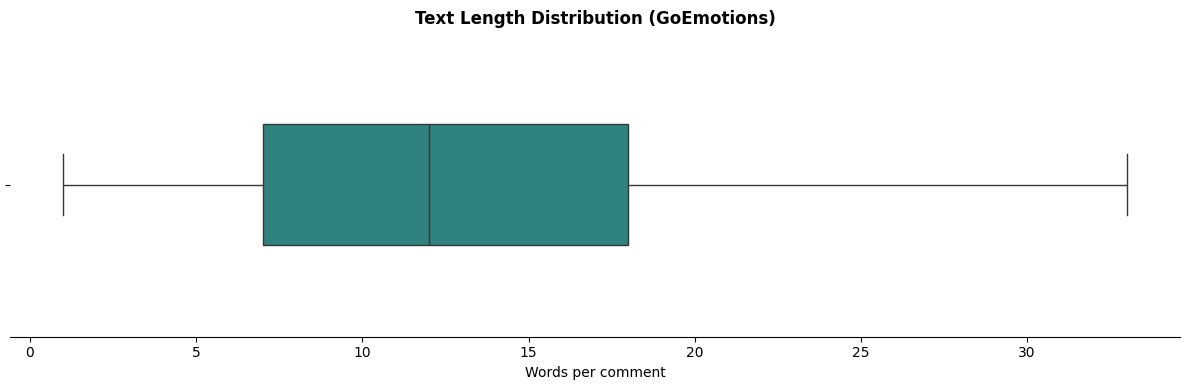

In [17]:
file_name = "text_length_distribution_words.png"

# calculate the number of words per comment:
df_full['text_length'] = df_full['comment_text'].astype(str).str.split().str.len()

plt.figure(figsize=(12, 4))

# horizontal boxplot
sns.boxplot(
    x=df_full['text_length'],
    palette="viridis",
    width=0.4,
    fliersize=3  # shrink outlier points to avoid cluttering the plot
)

plt.title("Text Length Distribution (GoEmotions)", fontsize=12, weight='bold')
plt.xlabel("Words per comment", fontsize=10) # or "Words per comment"
sns.despine(left=True) # remove useless spines

plt.tight_layout()
plt.savefig(os.path.join(EDA_FIGURE_PATH, file_name))
plt.show()
# drop the 'text_length' column to avoid errors if previous cells are run again
df_full.drop(columns=['text_length'], inplace=True)

## Dataset resampling
In this section, comments will be filtered, keeping only single-label instances.

Subsequently, the dataset will be resized to meet the computational limits available for the experiments.


Finally, the single-label comments will be resampled into reduced splits to ensure a fairer label distribution compared to the original dataset.

In [18]:
label_names = [col for col in df_train.columns if col != "comment_text" and col != "processed_text" and col != "label" and col != "label_id"]

def convert_to_single_label(df):
    """Filter to single-label rows and return a new DataFrame with a label column."""
    # calculate how many emotions are active for each row
    label_counts = df[label_names].sum(axis=1)

    # keep only comments with exactly 1 emotion
    df_single = df[label_counts == 1].copy()

    # create label column containing the name of the only active emotion
    # idxmax(axis=1) finds the column that has a value of 1
    df_single['label'] = df_single[label_names].idxmax(axis=1)
    df_single.drop(columns=label_names, inplace=True)

    return df_single.reset_index(drop=True)

# apply conversion to all original splits
df_train_sl = convert_to_single_label(df_train)
df_val_sl   = convert_to_single_label(df_val)
df_test_sl  = convert_to_single_label(df_test)

print(f"Remaining single-label comments:")
print(f"Train:  {df_train_sl.shape[0]}")
print(f"Val:    {df_val_sl.shape[0]}")
print(f"Test:   {df_test_sl.shape[0]}")

Remaining single-label comments:
Train:  36196
Val:    4546
Test:   4585


In [19]:
def balanced_stratified_sample(df, fraction=0.3, random_state=42):
    """Sample a fraction of df using weights inversely proportional to class frequency (sqrt-scaled)."""
    # calculate weights inversely proportional to class frequency
    class_counts = df['label'].value_counts()
    total_samples = len(df)

    # calculate a modified inclusion probability to favor rare classes
    # use square root to avoid exaggerating, balancing rarity
    class_weights = total_samples / (class_counts ** 0.5)
    class_weights = class_weights / class_weights.sum()

    # assign the weight of its class to each row
    row_weights = df['label'].map(class_weights)

    # determine the desired number of samples
    n_samples = int(len(df) * fraction)

    # sample favoring rare classes based on calculated weights
    df_sampled = df.sample(n=n_samples, weights=row_weights, random_state=random_state)

    return df_sampled.reset_index(drop=True)

# generate reduced subsets that proportionally oversample rare classes
df_train_small = balanced_stratified_sample(df_train_sl, fraction=0.30)
df_val_small   = balanced_stratified_sample(df_val_sl, fraction=0.30)
df_test_small  = balanced_stratified_sample(df_test_sl, fraction=0.30)

df_full_small = pd.concat([df_train_small, df_val_small, df_test_small])

In [20]:
print("Resampled comments:")
print(f"Train:  {df_train_small.shape[0]}")
print(f"Val:    {df_val_small.shape[0]}")
print(f"Test:   {df_test_small.shape[0]}")

Resampled comments:
Train:  10858
Val:    1363
Test:   1375


## Preprocessing
After reducing the initial dataset, the data is preprocessed using the `re` library for regular expressions and `SpaCy` for natural language.

The preprocessing operations to apply are:
- Lowercasing and punctuation removal
- Lemmatization
- Stopword removal

With the dataset restored to a cleaner form, the models are better able to generalize and waste less computational power on uninformative tokens, such as prepositions or articles.

In [21]:
nlp = spacy.load("en_core_web_sm")

In [22]:
def preprocess_text(text):
    """Lowercase, remove punctuation, lemmatize, and strip stopwords using spaCy."""
    # lowercase + punctuation removal
    text = text.lower()
    text = re.sub(r"[^\w\s]", "", text)

    # spaCy for lemmatization
    doc = nlp(text)

    # apply lemmatization
    lemmas = [
        token.lemma_
        for token in doc
        # remove stopwords and excess spaces
        if not token.is_stop and not token.is_space
    ]

    return " ".join(lemmas)

In [23]:
# preprocessing on all splits
df_train_small["processed_text"] = df_train_small["comment_text"].apply(preprocess_text)
df_val_small["processed_text"] = df_val_small["comment_text"].apply(preprocess_text)
df_test_small["processed_text"] = df_test_small["comment_text"].apply(preprocess_text)

### Data cleaning
We perform a second data cleaning to eliminate comments that became empty due to preprocessing.

In [35]:
# data cleaning: na removal

print(f"na values in training set:\n{df_train_small.isna().sum()}")
#print(f"na values in test set:\n{df_test_small.isna().sum()}")
#print(f"na values in validation set:\n{df_val_small.isna().sum()}")

df_train_small.dropna(inplace=True)
df_test_small.dropna(inplace=True)
df_val_small.dropna(inplace=True)

na values in training set:
comment_text      0
label             0
processed_text    0
label_id          0
dtype: int64


In [25]:
# label encoding: useful for subsequent notebooks
label_names = sorted(df_train_small["label"].unique())
NUM_CLASSES = len(label_names)

# mapping labels into a single column
label_to_id = {label: idx for idx, label in enumerate(label_names)}
id_to_label = {idx: label for label, idx in label_to_id.items()}

print(label_to_id)

# mapped labels in target splits
df_train_small["label_id"] = df_train_small["label"].map(label_to_id).astype("int32")
df_val_small["label_id"] = df_val_small["label"].map(label_to_id).astype("int32")
df_test_small["label_id"] = df_test_small["label"].map(label_to_id).astype("int32")

{'admiration': 0, 'amusement': 1, 'anger': 2, 'annoyance': 3, 'approval': 4, 'caring': 5, 'confusion': 6, 'curiosity': 7, 'desire': 8, 'disappointment': 9, 'disapproval': 10, 'disgust': 11, 'embarrassment': 12, 'excitement': 13, 'fear': 14, 'gratitude': 15, 'grief': 16, 'joy': 17, 'love': 18, 'nervousness': 19, 'neutral': 20, 'optimism': 21, 'pride': 22, 'realization': 23, 'relief': 24, 'remorse': 25, 'sadness': 26, 'surprise': 27}


### Data saving and loading
The newly resampled and preprocessed dataset is saved in the `data/processed` subfolder.

It can be reloaded in any project notebook from now on.

In [26]:
# save csv files in the specified Drive path
df_train_small.to_csv(os.path.join(DATA_PATH, 'df_train.csv'), index=False)
df_val_small.to_csv(os.path.join(DATA_PATH, 'df_val.csv'), index=False)
df_test_small.to_csv(os.path.join(DATA_PATH, 'df_test.csv'), index=False)

In [27]:
# load csv from Drive to skip preprocessing
df_train_small = pd.read_csv(os.path.join(DATA_PATH, 'df_train.csv'))
df_val_small = pd.read_csv(os.path.join(DATA_PATH, 'df_val.csv'))
df_test_small = pd.read_csv(os.path.join(DATA_PATH, 'df_test.csv'))

## Visualization of resampled and preprocessed dataset

In this section, the portion of the dataset selected for model training will be observed.

The preserved columns are:
- **comment_text**: original comment text
- **label**: string-encoded label
- **processed_text**: standardized text
- **label_id**: integer-encoded label

In [28]:
print(f"Train split shape:        {df_train_small.shape}")
print(f"Test split shape:         {df_test_small.shape}")
print(f"Validation split shape:   {df_val_small.shape}")

Train split shape:        (10858, 4)
Test split shape:         (1375, 4)
Validation split shape:   (1363, 4)


In [29]:
df_full_small = pd.concat([df_train_small, df_val_small, df_test_small])

In [30]:
display(df_train_small.head(5))

,comment_text,label,processed_text,label_id
0,"Amen, block all immigration.",annoyance,amen block immigration,3
1,Fight me coward! I will never ne frego!,anger,fight coward ne frego,2
2,The artist's rendition of the Jerseys numbers ...,neutral,artist rendition jerseys number especially,20
3,Very nice!! I love your art! What journal is t...,admiration,nice love art journal love texture page,0
4,Enjoy the ahuahuasca,joy,enjoy ahuahuasca,17


### Label distribution

From the visualization of the resampled dataset, it emerges that the difference between label frequencies is less pronounced compared to the original dataset, although some emotions remain heavily underrepresented.

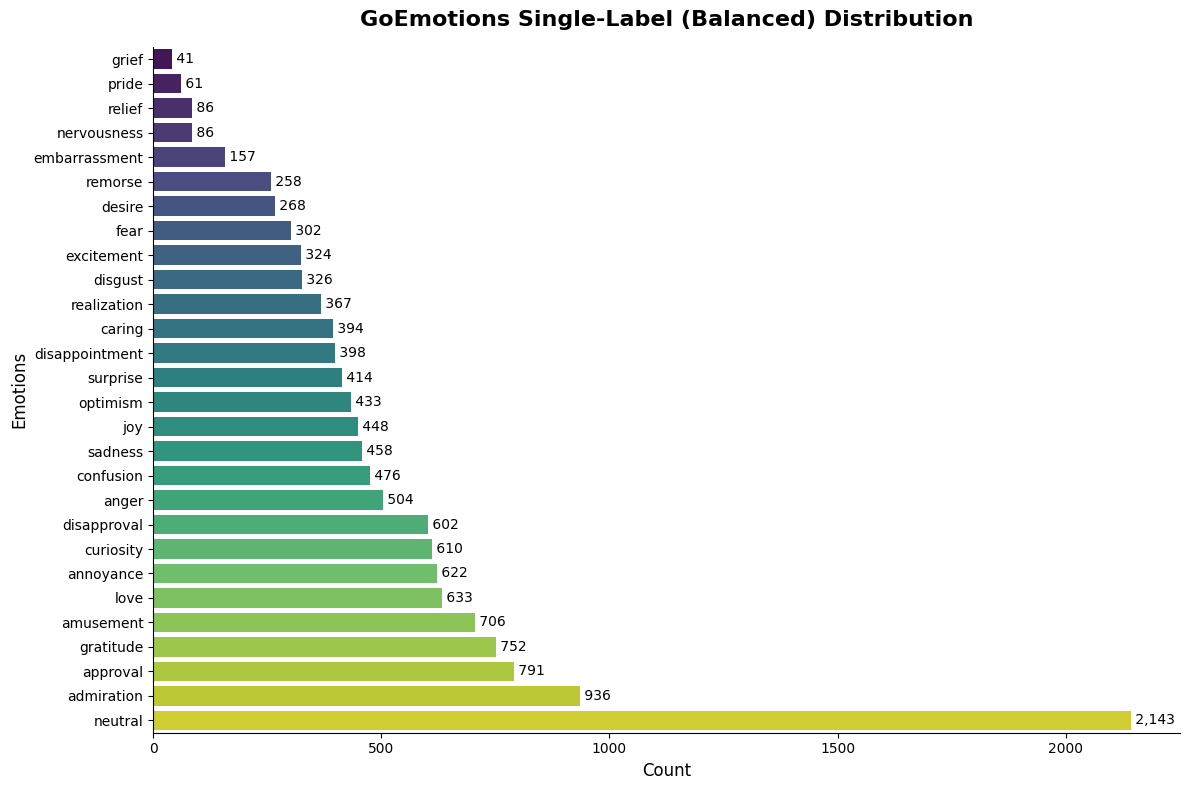

In [31]:
file_name = "label_distribution_single_label.png"

# sum of occurrences based on the label column
label_counts = df_full_small['label'].value_counts(ascending=True)

plt.figure(figsize=(12, 8))

# set palette
sns.barplot(
    x=label_counts.values,
    y=label_counts.index,
    palette="viridis"
)

# numeric values for each label
for index, value in enumerate(label_counts.values):
    plt.text(value, index, f' {value:,}', va='center', fontsize=10)

plt.title("GoEmotions Single-Label (Balanced) Distribution", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Count", fontsize=12)
plt.ylabel("Emotions", fontsize=12)

sns.despine(right=True, top=True)

plt.tight_layout()
plt.savefig(os.path.join(EDA_FIGURE_PATH, file_name))
plt.show()

### Comparison Wordcloud
Let's compare the two wordclouds of the 100 most common words in the original dataset versus the resampled and preprocessed one.

In both, it is possible to observe words that lead back to emotions or the expression of some concept or reflection. No evident anomalies emerge, so it is hypothesized that the resampled and preprocessed dataset is sufficiently representative to conduct reliable experiments.

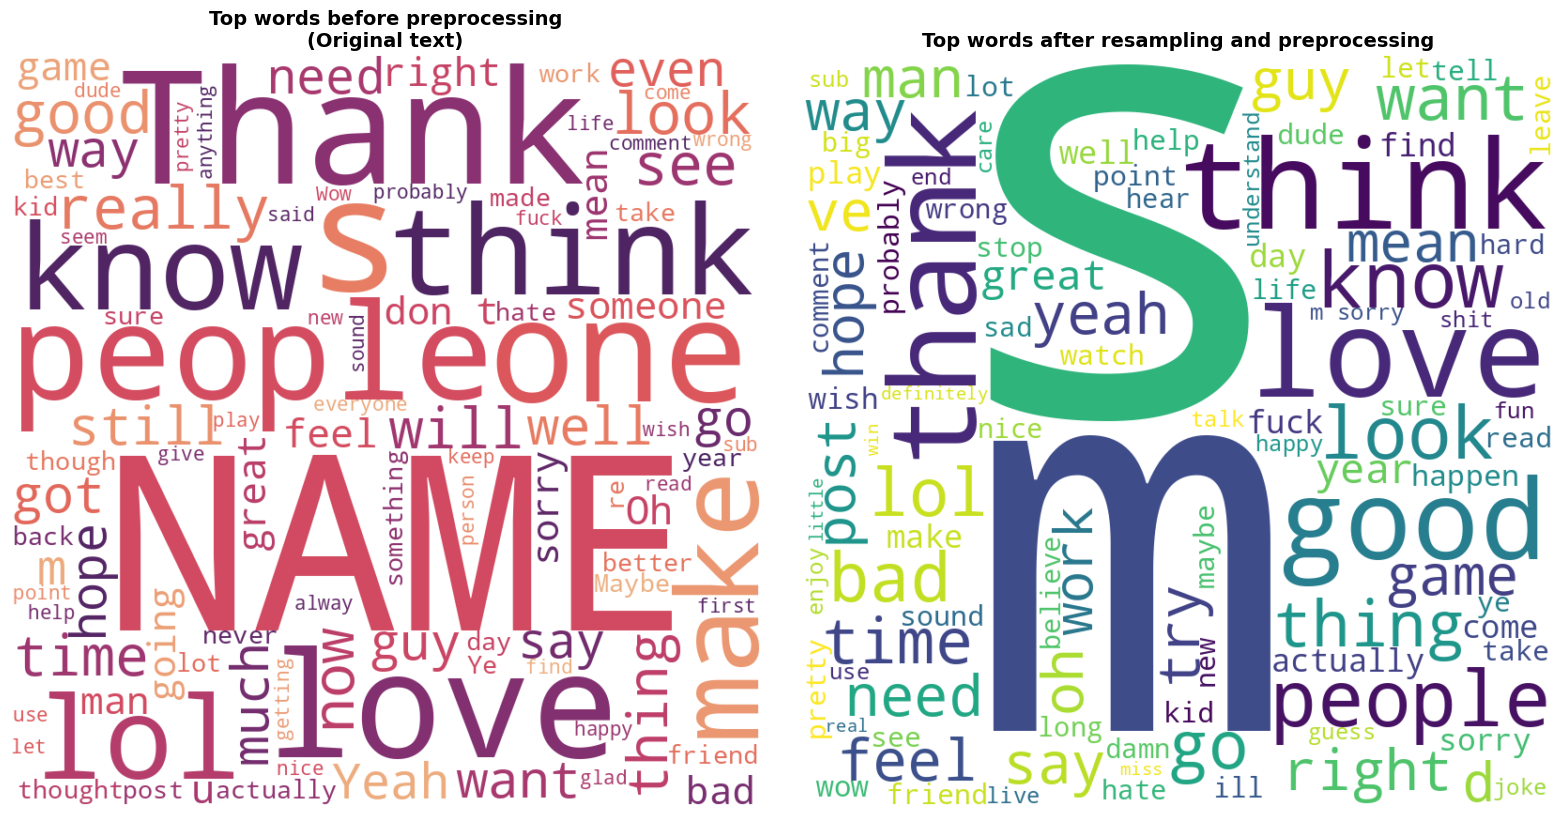

In [32]:
file_name = "wordcloud"
# two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# word cloud before preprocessing
wordcloud_pre = WordCloud(width=800, height=800, background_color='white',
                          colormap='flare', max_words=100).generate(" ".join(df_full['comment_text']))
axes[0].imshow(wordcloud_pre, interpolation='bilinear')
axes[0].set_title('Top words before preprocessing\n(Original text)', fontsize=14, fontweight='bold')
axes[0].axis('off')

# word cloud after preprocessing
wordcloud_post = WordCloud(width=800, height=800, background_color='white',
                           colormap='viridis', max_words=100).generate(" ".join(df_full_small['processed_text'].fillna('')))
axes[1].imshow(wordcloud_post, interpolation='bilinear')
axes[1].set_title('Top words after resampling and preprocessing', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(EDA_FIGURE_PATH, file_name))
plt.show()